# 1. Import Library

In [217]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data loading & Cek struktur table

In [218]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

df = pd.read_csv("train.csv")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()

Dataset Shape: 891 rows, 12 columns



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2.1 Cek tipe data & nilai null


In [219]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


terlihat beberapa data memiliki nilai null / kosong, seperti age, cabin da embarked

### 2.2 Ringkasan statistik (mean, modus, etc..)

In [220]:
df.describe().rename(index={'25%':'Q1', '50%':'median', '75%':"Q3"})

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
Q1,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
median,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
Q3,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


terdapat outlier pada fare dimana dimax terlihat 512, dimana sangat jauh dibanding meannya


---

## 3. Exploratory Data Analysis (EDA) & Visualisasi data
### 3.1 Distribusi variabel selamat & tidak



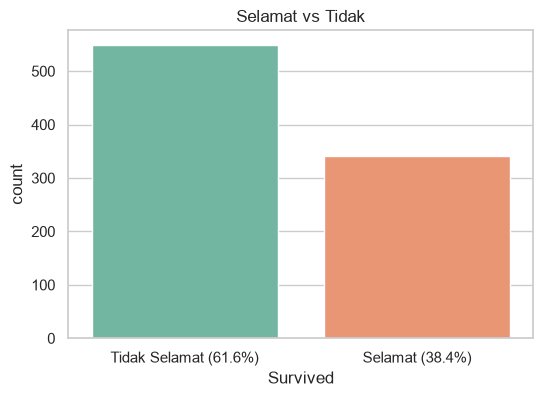

In [221]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Survived', hue = 'Survived', palette='Set2', legend=False)
plt.title('Selamat vs Tidak')
persentase = df['Survived'].value_counts(normalize=True) * 100
plt.xticks([0,1],[f'Tidak Selamat ({persentase[0].round(1)}%)', f'Selamat ({persentase[1].round(1)}%)'])   
plt.show()

### 3.2 Analisis survival rate berdasarkan gender

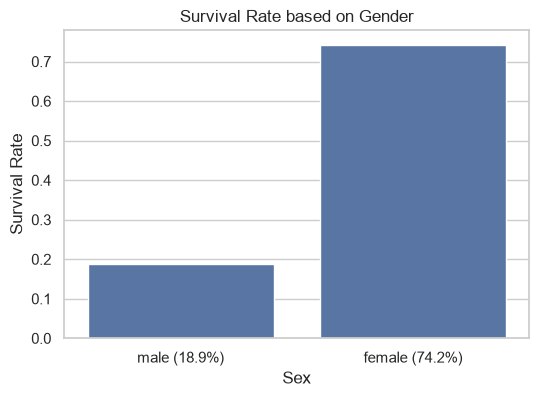

In [222]:
plt.figure(figsize=(6,4))
sns.barplot(data=df, x = 'Sex', y ='Survived', errorbar=None,)
plt.title('Survival Rate based on Gender')
plt.ylabel('Survival Rate')
persentase = df.groupby('Sex')['Survived'].mean()*100
plt.xticks([0,1],[f'male ({persentase['male'].round(1)}%)',f'female ({persentase['female'].round(1)}%)'])
plt.show()

terlihat perempuan memiliki survival rate lebih tinggi dibanding pria karena terdapat protokol kapal yang bernama woman and children first

### 3.3 Analisis survival rate berdasarkan pClass


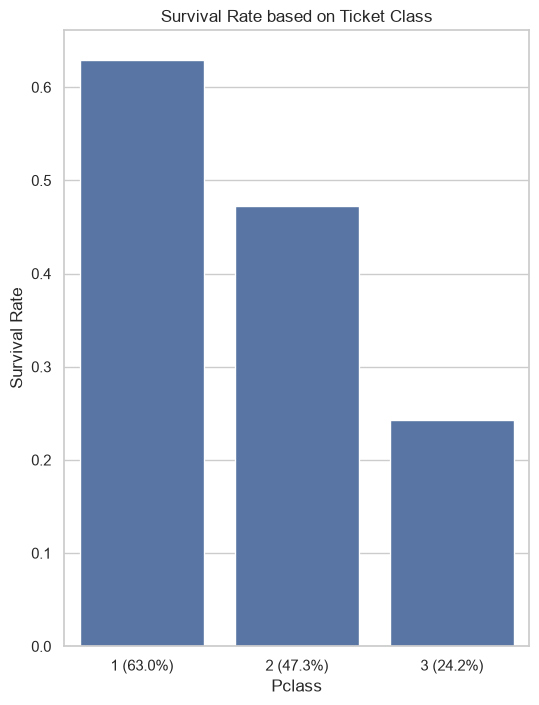

In [223]:
plt.figure(figsize=(6,8))
sns.barplot(data=df, x='Pclass', y='Survived', errorbar=None)
plt.title('Survival Rate based on Ticket Class')
plt.ylabel('Survival Rate')
persentase= df.groupby('Pclass')['Survived'].mean()*100
plt.xticks([0,1,2],[f'1 ({persentase[1].round(1)}%)',f'2 ({persentase[2].round(1)}%)',f'3 ({persentase[3].round(1)}%)'])
plt.show()

semakin tinggi pClass semakin tinggi peluang untuk hidup karena kelas 1 (bangsawan & orang kaya) memiliki akses sekoci yang lebih cepat dan lebih cepat mendapat informasi untuk evakuasi

kelas 3 berada di ruangan dasar, sehingga saat tertabrak gunung es, bagian bawah lah yang langsung terendam oleh air

### 3.4 Distribusi usia berdasarkan yang terselamatkan

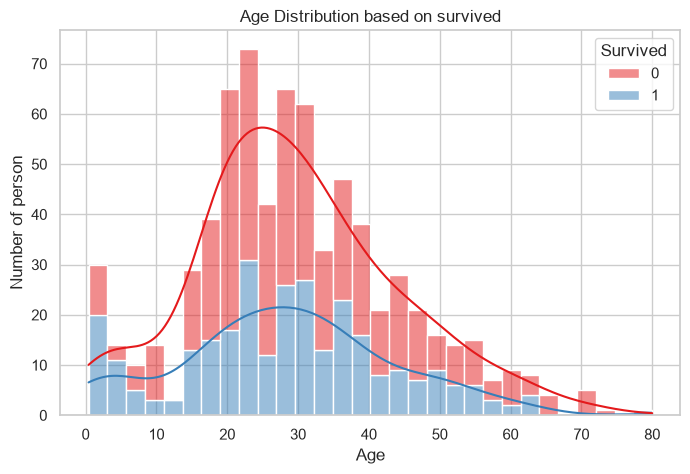

In [224]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Age',hue='Survived', kde=True, bins=30, palette='Set1', multiple='stack')
plt.title('Age Distribution based on survived')
plt.xlabel('Age')
plt.ylabel('Number of person')
plt.show()

kelompok umur 0-5 memiliki potensi hidup lebih besar, terlihat pada histogram, rasio bar untuk survive(1) lebih besar

kelompok 20-35 menyumbang jumlah penumpang paling banyak sekaligus jumlah kematian paling banyak

### 3.5 Analisis tarif tiket perkelas dengan huungan survival rate

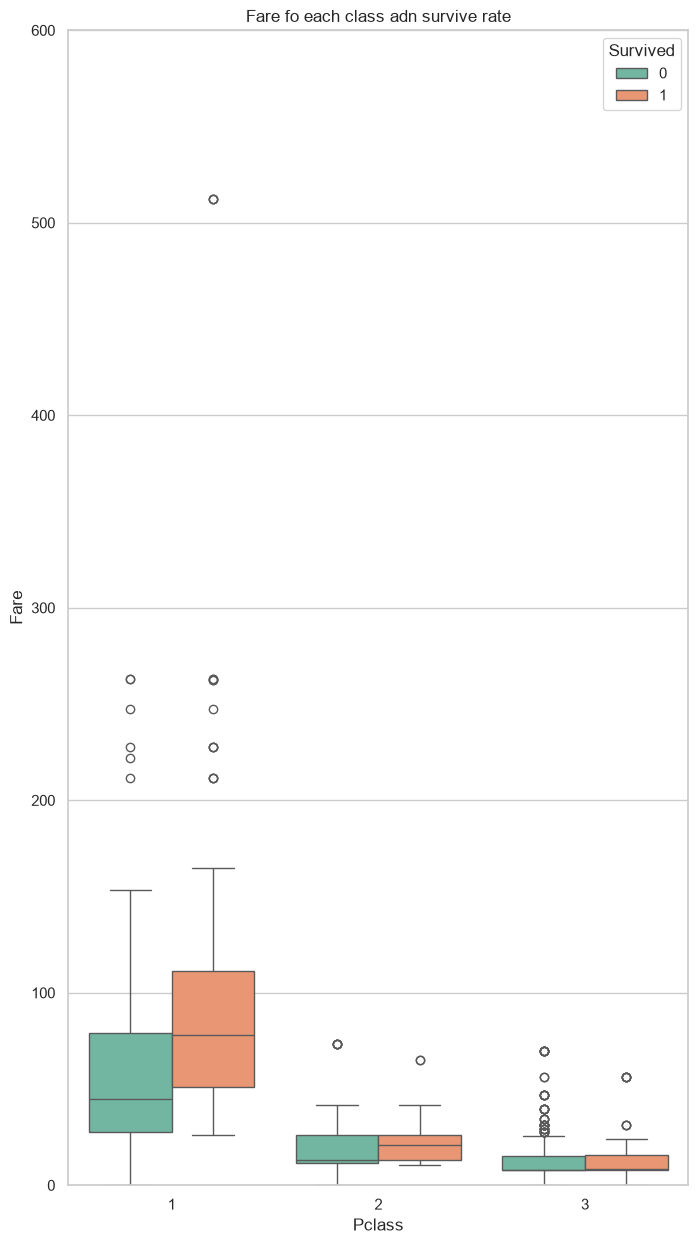

In [225]:
plt.figure(figsize=(8,15))
sns.boxplot(data = df, x='Pclass', y='Fare', hue='Survived', palette='Set2')
plt.title('Fare fo each class adn survive rate')
plt.ylim(0,600)
plt.show()

pada boxplot terlihat pada kelas 1 memiliki peluang hidup yang lebih tinggi

pada kelas 1 variasi harga tiket tetap terjadi, bahkan banyak yang menjadi kannya outlier

pada kelas 1 orang yang selamat pun umumnya membayar kabin yang lebih mahal dibanding yang tewas

### 3.6 Korelasi usia vs fare dengan survival rate

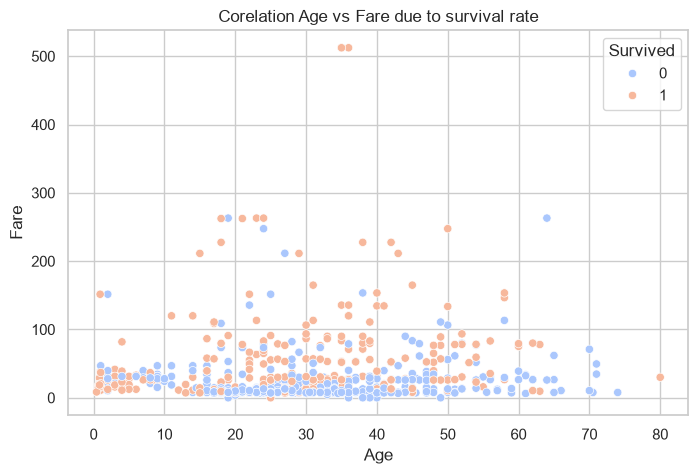

In [226]:
plt.figure(figsize=(8,5))
sns.scatterplot(data = df, x='Age', y='Fare', hue='Survived', palette='coolwarm')
plt.title('Corelation Age vs Fare due to survival rate')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

terlihat pada scatterplot diatas menandakan semakin tiggi harga tiket semakin besar kemungkinan untuk selamat, untuk umur 0-5 pun menjadikan peluang hidup lebih besar

tidak ada korelasi yang mendasari umur dan biaya tiket, masing masing berdiri secara independen

---

## 4. Data Preprocessing
### 4.1 Identifikasi missing values

In [227]:
missing = df.isnull().sum()
missing_percent = (df.isnull().sum()/len(df))*100

missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage %':missing_percent})
print(missing_df[missing_df['Missing Count'] > 0])

          Missing Count  Percentage %
Age                 177     19.865320
Cabin               687     77.104377
Embarked              2      0.224467


### 4.2 Pembersihan Data (Handling Missing Values & Feature Dropping)


In [228]:
df_clean = df.copy()

df_clean.drop(columns=['Cabin'], inplace=True)
df_clean.drop(columns=['Name','PassengerId','Ticket'], inplace=True)

median_age = df_clean['Age'].median()
df_clean['Age']=df_clean['Age'].fillna(median_age)

mode_embarked = df_clean['Embarked'].mode()[0]
df_clean['Embarked']=df_clean['Embarked'].fillna(mode_embarked)

print('Missing value after cleaning')
print(df_clean.isnull().sum())
print(df_clean.head())


Missing value after cleaning
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


C:\Users\vrowk\AppData\Local\Temp\ipykernel_15240\1456326087.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop(columns=['Cabin'], inplace=True)
C:\Users\vrowk\AppData\Local\Temp\ipykernel_15240\1456326087.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop(columns=['Name','PassengerId','Ticket'], inplace=True)


penghapusan kolom cabin karena, sangat banyak nilai null

penghapusan identifier yang tida brepengaruh(nama, id, tiket)

mengisi nilai kosong age dengan nilai median

mengisi embarked dengan modus, karena yang kosong hanya sedikit


### 4.3 Feature Encoding (Konversi Fitur Kategorikal ke Numerik)


In [229]:
print('Before')
print(df_clean.dtypes)
df_clean['Sex'] = df_clean['Sex'].map({'male' : 0, 'female' :1})
df_clean =pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True,dtype=int)

print('After')
print(df_clean.dtypes)

print(df_clean.head())

Before
Survived      int64
Pclass        int64
Sex             str
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked        str
dtype: object
After
Survived        int64
Pclass          int64
Sex             int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked_Q      int64
Embarked_S      int64
dtype: object
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_Q  Embarked_S
0         0       3    0  22.0      1      0   7.2500           0           1
1         1       1    1  38.0      1      0  71.2833           0           0
2         1       3    1  26.0      0      0   7.9250           0           1
3         1       1    1  35.0      1      0  53.1000           0           1
4         0       3    0  35.0      0      0   8.0500           0           1


Karena machine learning hanya bisa memproses angka, kita mengubah gender menjadi binary 0 dan 1
karena embarked merupakan data kategorikal nominal, maka embarked kita ubah menjadi kolom biner dummy untuk menghindari kesalahan model yang mengira ada peringkat/urutan nilai

### 4.4 Feature Scaling (Standardisasi Fitur Numerik)


In [230]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_clean[['Age','Fare']] = scaler.fit_transform(df_clean[['Age','Fare']])

print('FINAL')
print(df_clean.head())

print(df_clean[['Age', 'Fare']].describe().round(2))

FINAL
   Survived  Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_Q  \
0         0       3    0 -0.565736      1      0 -0.502445           0   
1         1       1    1  0.663861      1      0  0.786845           0   
2         1       3    1 -0.258337      0      0 -0.488854           0   
3         1       1    1  0.433312      1      0  0.420730           0   
4         0       3    0  0.433312      0      0 -0.486337           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  
          Age    Fare
count  891.00  891.00
mean     0.00    0.00
std      1.00    1.00
min     -2.22   -0.65
25%     -0.57   -0.49
50%     -0.10   -0.36
75%      0.43   -0.02
max      3.89    9.67


Standarisasi dilakukan agar umur dan fare memiliki variasi yang sama, sehingga tidak jomplang di satu fitur

kita menggunakan standardscaller karena banyak outlier dimana sstandardscaller lebih kebal terhadap outlier dibandingka minmaxscaller

# Adding Essential library

In [244]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# 5. Split dataset

In [232]:
X = df_clean.drop(columns=['Survived'])
y = df_clean['Survived']

In [233]:
X_train, X_test, y_train,y_test = train_test_split(X,y,test_size=0.3, random_state=42)

# 6. Scalling

In [234]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 7. Test Model


In [235]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [236]:
y_pred = model.predict(X_test_scaled)
y_pred

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0])

# 8. Overall Score

In [237]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[136,  21],
       [ 30,  81]])

In [238]:
accuracy_score(y_test, y_pred)

0.8097014925373134

In [239]:
f1_score(y_test, y_pred, average='macro')

0.8013343217197924

In [240]:
precision_score(y_test, y_pred, average='macro')

0.8066973777462791

In [241]:
recall_score(y_test, y_pred, average='macro')

0.7979858839731451

In [245]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.87      0.84       157
           1       0.79      0.73      0.76       111

    accuracy                           0.81       268
   macro avg       0.81      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268

